# JOB OFFER ACCEPTANCE PREDICTION: EXPLORATORY DATA ANALYSIS

This notebook performs exploratory data analysis, data preprocessing, domain-driven feature engineering, and statistical feature selection focusing on core candidate experience, compensation alignment, and workplace factors.

In [25]:
# REQUIRED LIBRARIES

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings('ignore')
plt.style.use('ggplot')
print('Libraries Imported Successfully!')

Libraries Imported Successfully!


In [26]:
# LOADING DATASET & DROPPING UNWANTED FEATURES

data_path = '../dataset/job_offer_acceptance_dataset.csv'
if not os.path.exists(data_path):
    data_path = 'dataset/job_offer_acceptance_dataset.csv'

df_raw = pd.read_csv(data_path)

features_to_drop = [
    'candidate_id', 'major', 'university_tier', 'city', 'education_level',
    'kaggle_score', 'linkedin_connections', 'internship_count',
    'github_repositories', 'hackathons_participated', 'leadership_experience',
    'company_industry', 'publications_count', 'application_month', 'application_year'
]

df = df_raw.drop(columns=[c for c in features_to_drop if c in df_raw.columns])
print('Filtered Dataset Shape:', df.shape)
print('Active Feature Columns:\n', df.columns.tolist())
df.head()

Filtered Dataset Shape: (200000, 13)
Active Feature Columns:
 ['age', 'gender', 'country', 'years_experience', 'expected_salary_usd', 'offered_salary_usd', 'remote_preference', 'relocation_willingness', 'company_size', 'company_rating', 'offer_accepted', 'salary_offer_gap_usd', 'offer_to_expected_salary_ratio']


,age,gender,country,years_experience,expected_salary_usd,offered_salary_usd,remote_preference,relocation_willingness,company_size,company_rating,offer_accepted,salary_offer_gap_usd,offer_to_expected_salary_ratio
0,49,Other,Singapore,0.7,55304,64041,Onsite,Yes,Startup,2.7,0,8737,1.1580
1,29,Female,India,2.3,73673,87639,Remote,Yes,Startup,4.5,0,13966,1.1896
2,21,Other,Japan,0.9,55910,52128,Onsite,No,Medium,3.7,0,-3782,0.9324
3,35,Female,Canada,4.7,78573,92941,Hybrid,No,Enterprise,3.9,1,14368,1.1829
4,22,Male,Germany,1.2,51525,57365,Onsite,Yes,Enterprise,4.1,0,5840,1.1133


In [27]:
# DATASET SUMMARY & MISSING VALUES CHECK
print('Missing Values:\n', df.isnull().sum())
print('\nDuplicates:', df.duplicated().sum())
df.describe()

Missing Values:
 age                               0
gender                            0
country                           0
years_experience                  0
expected_salary_usd               0
offered_salary_usd                0
remote_preference                 0
relocation_willingness            0
company_size                      0
company_rating                    0
offer_accepted                    0
salary_offer_gap_usd              0
offer_to_expected_salary_ratio    0
dtype: int64

Duplicates: 0


,age,years_experience,expected_salary_usd,offered_salary_usd,company_rating,offer_accepted,salary_offer_gap_usd,offer_to_expected_salary_ratio
count,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.00000,200000.000000
mean,37.481640,3.975783,76514.370485,80326.329305,3.753712,0.331675,3811.95882,1.049738
std,9.808264,3.862105,26630.676792,28846.742642,0.723885,0.470816,7141.54611,0.086582
min,21.000000,0.000000,16329.000000,17074.000000,2.500000,0.000000,-19132.00000,0.900000
25%,29.000000,1.200000,58070.000000,60359.000000,3.100000,0.000000,-1739.00000,0.974900
50%,37.000000,2.800000,70037.500000,73563.000000,3.800000,0.000000,3410.00000,1.049300
75%,46.000000,5.500000,88391.000000,93195.500000,4.400000,1.000000,8671.00000,1.124700
max,54.000000,20.000000,204272.000000,242460.000000,5.000000,1.000000,39373.00000,1.200000


--- 
## 1. TARGET DISTRIBUTION & SALARY ALIGNMENT

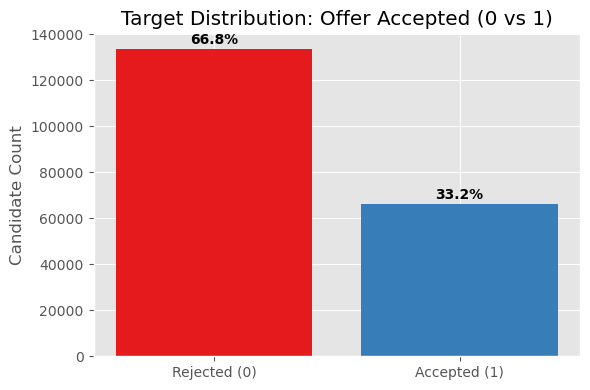

In [28]:
# TARGET VARIABLE DISTRIBUTION (Offer Accepted vs Rejected)

counts = df['offer_accepted'].value_counts()
percentages = df['offer_accepted'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Rejected (0)', 'Accepted (1)'], counts.values, color=['#e41a1c', '#377eb8'])
ax.set_title('Target Distribution: Offer Accepted (0 vs 1)')
ax.set_ylabel('Candidate Count')
for bar, pct in zip(bars, percentages.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2000, f'{pct:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

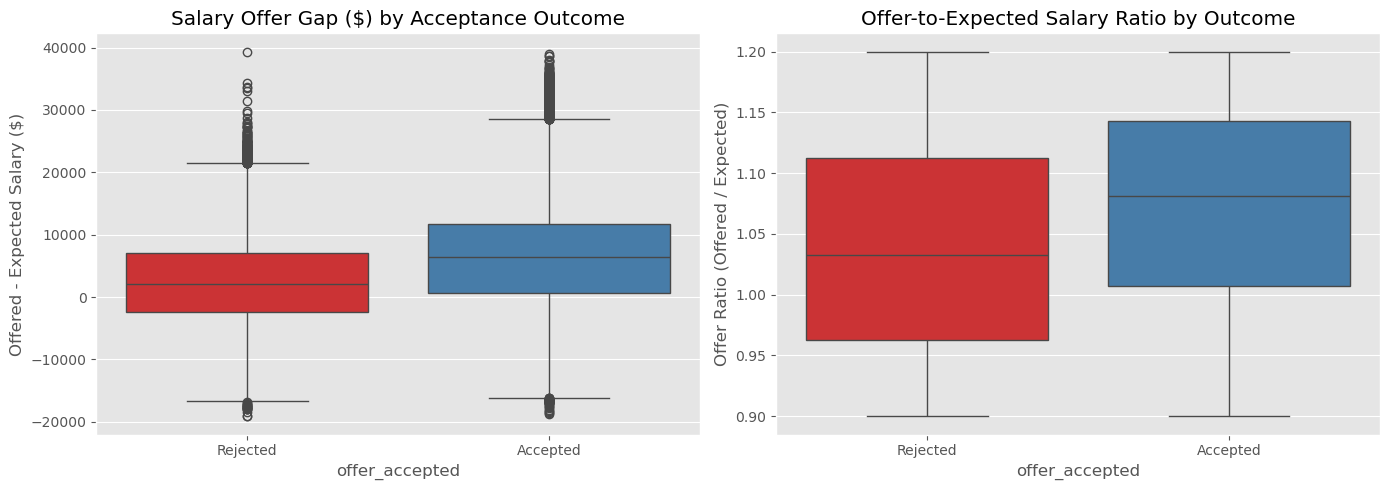

In [29]:
# SALARY GAP & OFFER RATIO BY OUTCOME

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(x='offer_accepted', y='salary_offer_gap_usd', data=df, ax=axes[0], palette=['#e41a1c', '#377eb8'])
axes[0].set_title('Salary Offer Gap ($) by Acceptance Outcome')
axes[0].set_xticklabels(['Rejected', 'Accepted'])
axes[0].set_ylabel('Offered - Expected Salary ($)')

sns.boxplot(x='offer_accepted', y='offer_to_expected_salary_ratio', data=df, ax=axes[1], palette=['#e41a1c', '#377eb8'])
axes[1].set_title('Offer-to-Expected Salary Ratio by Outcome')
axes[1].set_xticklabels(['Rejected', 'Accepted'])
axes[1].set_ylabel('Offer Ratio (Offered / Expected)')

plt.tight_layout()
plt.show()

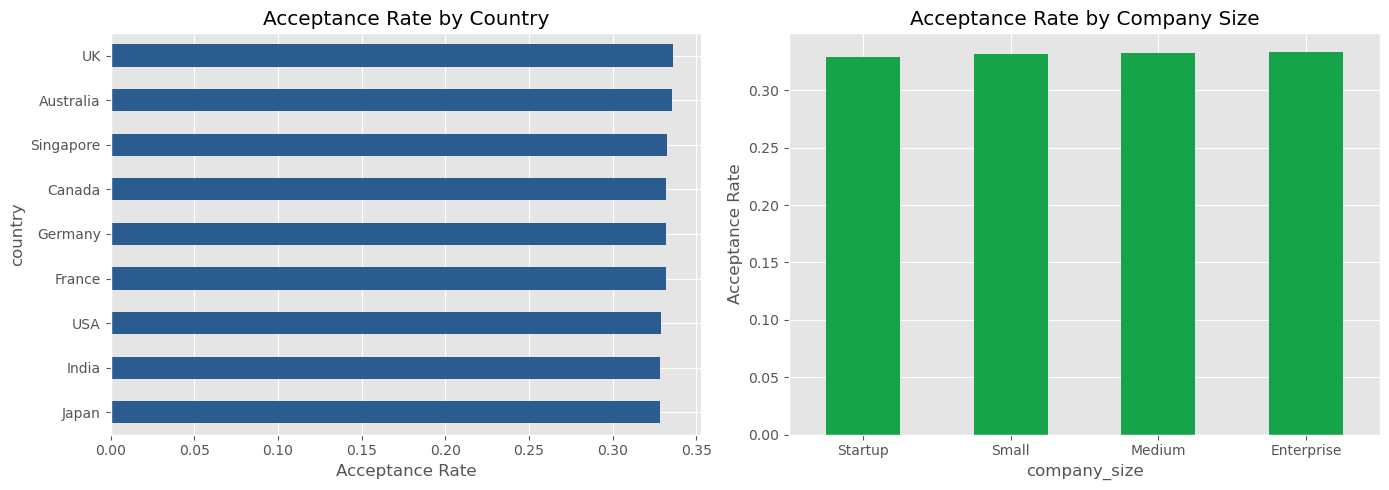

In [30]:
# ACCEPTANCE RATE BY COUNTRY & COMPANY SIZE

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df.groupby('country')['offer_accepted'].mean().sort_values().plot(kind='barh', color='#2b5c8f', ax=axes[0])
axes[0].set_title('Acceptance Rate by Country')
axes[0].set_xlabel('Acceptance Rate')

df.groupby('company_size')['offer_accepted'].mean().sort_values().plot(kind='bar', color='#16a34a', ax=axes[1])
axes[1].set_title('Acceptance Rate by Company Size')
axes[1].set_ylabel('Acceptance Rate')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()

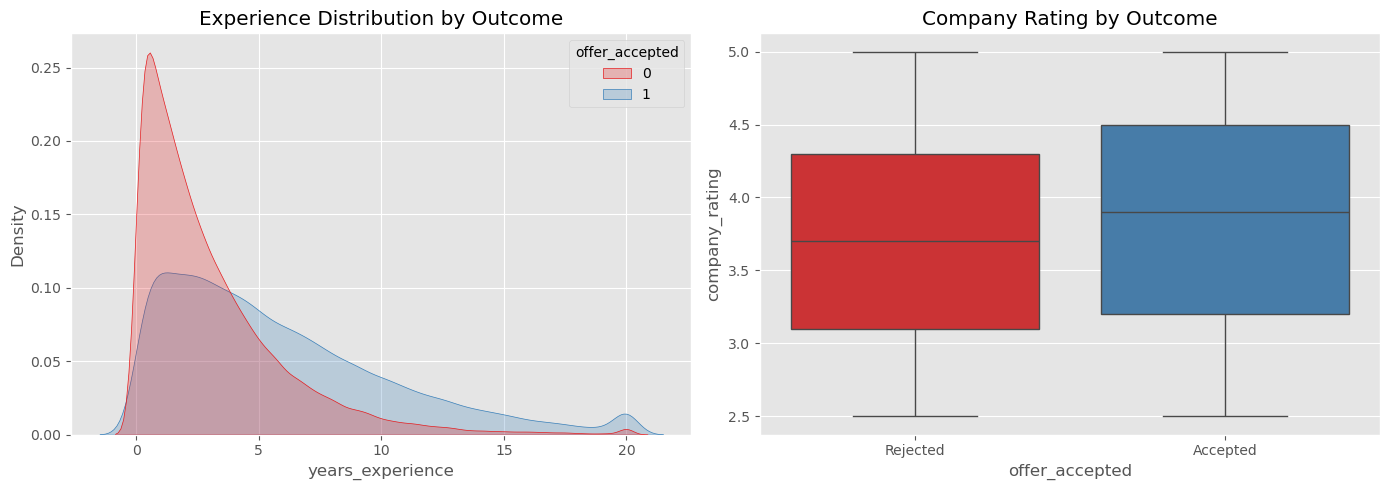

In [31]:
# EXPERIENCE & COMPANY RATING DISTRIBUTIONS

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(data=df, x='years_experience', hue='offer_accepted', fill=True, common_norm=False, palette=['#e41a1c', '#377eb8'], ax=axes[0])
axes[0].set_title('Experience Distribution by Outcome')

sns.boxplot(x='offer_accepted', y='company_rating', data=df, ax=axes[1], palette=['#e41a1c', '#377eb8'])
axes[1].set_title('Company Rating by Outcome')
axes[1].set_xticklabels(['Rejected', 'Accepted'])

plt.tight_layout()
plt.show()

--- 
## 2. FEATURE ENGINEERING & FEATURE SELECTION

In [32]:
# FEATURE ENGINEERING

df['salary_hike_pct'] = ((df['offered_salary_usd'] - df['expected_salary_usd']) / df['expected_salary_usd']) * 100
df['exp_to_age_ratio'] = df['years_experience'] / df['age']

print('Feature Engineering complete. Shape:', df.shape)
df[['salary_offer_gap_usd', 'offer_to_expected_salary_ratio', 'salary_hike_pct', 'exp_to_age_ratio']].describe()

Feature Engineering complete. Shape: (200000, 15)


,salary_offer_gap_usd,offer_to_expected_salary_ratio,salary_hike_pct,exp_to_age_ratio
count,200000.00000,200000.000000,200000.000000,200000.000000
mean,3811.95882,1.049738,4.973747,0.114296
std,7141.54611,0.086582,8.658216,0.119950
min,-19132.00000,0.900000,-10.001380,0.000000
25%,-1739.00000,0.974900,-2.513686,0.031111
50%,3410.00000,1.049300,4.927841,0.076000
75%,8671.00000,1.124700,12.472732,0.155882
max,39373.00000,1.200000,19.999762,0.952381


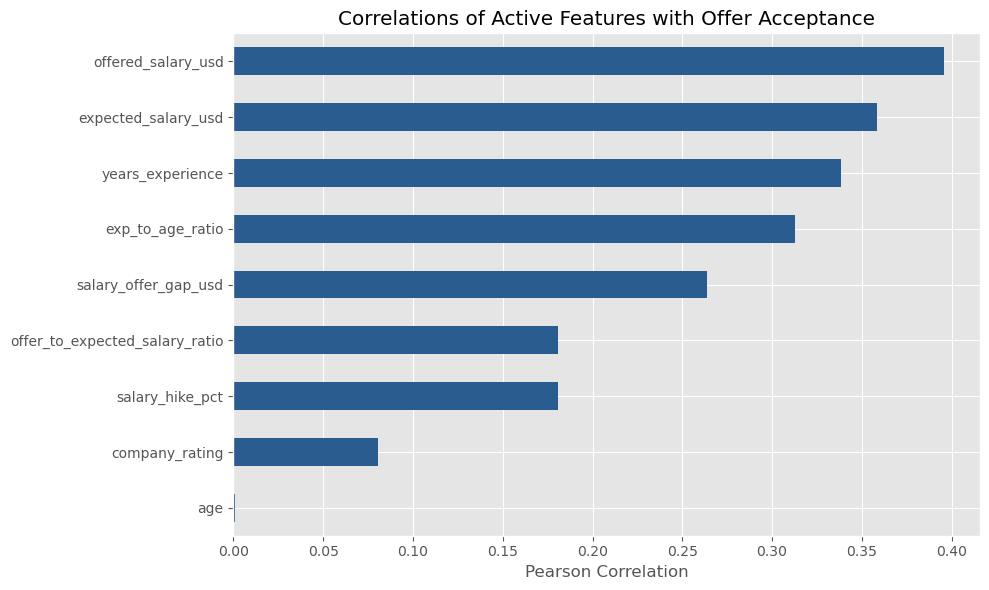

Feature Correlations:
offered_salary_usd                0.395956
expected_salary_usd               0.358241
years_experience                  0.338539
exp_to_age_ratio                  0.312957
salary_offer_gap_usd              0.263505
offer_to_expected_salary_ratio    0.181028
salary_hike_pct                   0.181028
company_rating                    0.080548
age                               0.001111
Name: offer_accepted, dtype: float64


In [33]:
# 1. CORRELATIONS WITH TARGET

corrs = df.select_dtypes(include=['number']).corr()['offer_accepted'].drop('offer_accepted').sort_values()

plt.figure(figsize=(10, 6))
corrs.plot(kind='barh', color='#2b5c8f')
plt.title('Correlations of Active Features with Offer Acceptance')
plt.xlabel('Pearson Correlation')
plt.tight_layout()
plt.show()

print('Feature Correlations:')
print(corrs.sort_values(ascending=False))

ANOVA F-Test Ranking:
                           Feature       F_Score        P_Value
0               offered_salary_usd  37185.953795   0.000000e+00
1              expected_salary_usd  29446.099263   0.000000e+00
2                 years_experience  25888.580449   0.000000e+00
3                 exp_to_age_ratio  21715.076392   0.000000e+00
4             salary_offer_gap_usd  14923.033534   0.000000e+00
5   offer_to_expected_salary_ratio   6776.225573   0.000000e+00
6                  salary_hike_pct   6776.218297   0.000000e+00
7                   company_rating   1306.050059  4.590692e-285
8                remote_preference   1178.317076  1.777089e-257
9                     company_size      2.124011   1.450079e-01
10                          gender      1.377518   2.405258e-01
11                         country      0.400628   5.267659e-01
12                             age      0.247016   6.191843e-01
13          relocation_willingness      0.006789   9.343346e-01


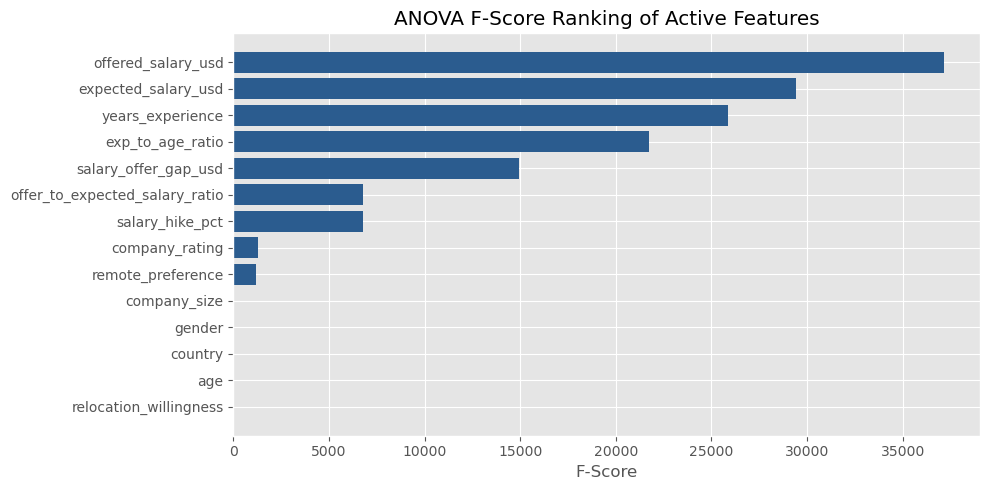

In [34]:
# 2. ANOVA F-TEST FEATURE RANKING (SelectKBest)

df_enc = df.copy()
for col in df_enc.select_dtypes(include=['object']).columns:
    df_enc[col] = LabelEncoder().fit_transform(df_enc[col].astype(str))

X_sel = df_enc.drop('offer_accepted', axis=1)
y_sel = df_enc['offer_accepted']

selector = SelectKBest(score_func=f_classif, k='all')
selector.fit(X_sel, y_sel)

f_scores = pd.DataFrame({
    'Feature': X_sel.columns,
    'F_Score': selector.scores_,
    'P_Value': selector.pvalues_
}).sort_values('F_Score', ascending=False).reset_index(drop=True)

print('ANOVA F-Test Ranking:')
print(f_scores)

plt.figure(figsize=(10, 5))
plt.barh(f_scores['Feature'][::-1], f_scores['F_Score'][::-1], color='#2b5c8f')
plt.title('ANOVA F-Score Ranking of Active Features')
plt.xlabel('F-Score')
plt.tight_layout()
plt.show()

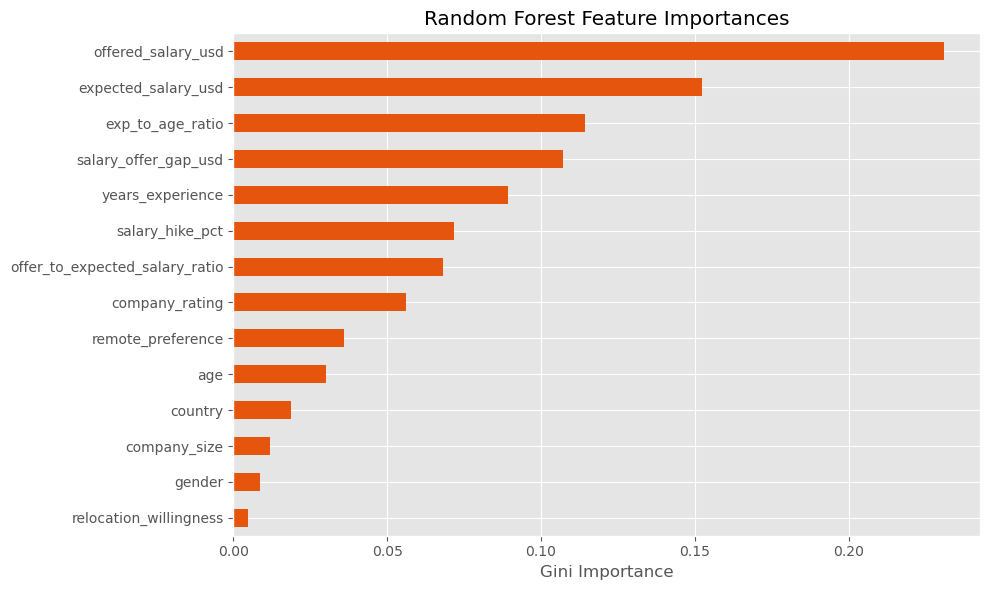

Top Features by Random Forest Importance:
offered_salary_usd                0.231085
expected_salary_usd               0.152175
exp_to_age_ratio                  0.114408
salary_offer_gap_usd              0.107108
years_experience                  0.089248
salary_hike_pct                   0.071816
offer_to_expected_salary_ratio    0.068105
company_rating                    0.056075
remote_preference                 0.036045
age                               0.029980
country                           0.018639
company_size                      0.011902
gender                            0.008531
relocation_willingness            0.004883
dtype: float64


In [35]:
# 3. TREE-BASED FEATURE IMPORTANCES (Random Forest)

sample_idx = np.random.RandomState(42).choice(len(X_sel), size=min(30000, len(X_sel)), replace=False)
rf = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_sel.iloc[sample_idx], y_sel.iloc[sample_idx])

rf_importances = pd.Series(rf.feature_importances_, index=X_sel.columns).sort_values()

plt.figure(figsize=(10, 6))
rf_importances.plot(kind='barh', color='#e6550d')
plt.title('Random Forest Feature Importances')
plt.xlabel('Gini Importance')
plt.tight_layout()
plt.show()

print('Top Features by Random Forest Importance:')
print(rf_importances.sort_values(ascending=False))